In [1]:
# Install loompy
!pip install scanpy
# Clone the SpaGE repository
!git clone https://github.com/tabdelaal/SpaGE.git
# Navigate into the SpaGE directory
%cd SpaGE

Cloning into 'SpaGE'...
remote: Enumerating objects: 347, done.
remote: Counting objects: 100% (252/252), done.
remote: Compressing objects: 100% (95/95), done.
remote: Total 347 (delta 149), reused 244 (delta 144), pack-reused 95 (from 1)
Receiving objects: 100% (347/347), 2.59 MiB | 714.00 KiB/s, done.
Resolving deltas: 100% (187/187), done.
/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation/SpaGE


# Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
import scipy.stats as st
from SpaGE.main import SpaGE
from sklearn.metrics import root_mean_squared_error
from skimage.metrics import structural_similarity as ssim
import warnings
warnings.filterwarnings('ignore')



# Data Upload and Pre-Processing

In [4]:
import os
print(os.getcwd())
os.chdir('/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation')


adata_sc = sc.read('gene_data/ageing_rna_20250114.h5ad')
print(adata_sc)

adata_st = sc.read('gene_data/ag02reg00_rawcounts.h5ad')
print(adata_st)

/Users/Amith/Documents/Documents – Viji’s MacBook Pro/Work/LIDo PhD/Year 1/Rotation 2/Project Work/Code/Imputation/SpaGE
AnnData object with n_obs × n_vars = 173199 × 19957
    obs: 'id_barcode', 'scDblFinder_score', 'scDblFinder_class', 'celltype', 'sample', 'barcode', 'id_barcode.1', 'cell_id', 'class_label', 'class_name', 'class_bootstrapping_probability', 'subclass_label', 'subclass_name', 'subclass_bootstrapping_probability', 'supertype_label', 'supertype_name', 'supertype_bootstrapping_probability', 'cluster_label', 'cluster_name', 'cluster_alias', 'cluster_bootstrapping_probability', 'orig.ident', 'nCount_RNA', 'nFeature_RNA', 'leverage.score', 'sketch_snn_res.2', 'seurat_clusters', 'celltype.full', 'celltype.full.score', 'nCount_SCT', 'nFeature_SCT', 'SCT_snn_res.0.8', 'Name', 'Sex', 'Line', 'DOB', 'DOD', 'age_days', 'age_months', 'Sample #'
    var: 'Unnamed: 0'
AnnData object with n_obs × n_vars = 40576 × 500
    obs: 'EntityID', 'fov', 'volume', 'center_x', 'center_y', 'min_

In [5]:
# Normalise the single-cell data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_sc, target_sum=1e4)
sc.pp.log1p(adata_sc)

# Normalise the spatial data (because different cells are sequenced at different depths)
sc.pp.normalize_total(adata_st, target_sum=1e4)
sc.pp.log1p(adata_st)

# Removes the groups 15 HY Gnrh1 Glut because it contains
# only one sample
# This means statistics cannot be performed on this group
adata_sc = adata_sc[adata_sc.obs['class_name'] != "15 HY Gnrh1 Glut"]

In [6]:
np_adata_sc = adata_sc.X.toarray()
print(type(np_adata_sc))

<class 'numpy.ndarray'>


In [7]:
# Convert single cell and spatial data into Pandas DataFrames
adata_sc_df = pd.DataFrame(np_adata_sc, columns=adata_sc.var_names)
adata_st_df = pd.DataFrame(adata_st.X, columns=adata_st.var_names)

In [8]:
print(adata_st_df)

           Igf2  Ngfr     Ccnd2   Th  Lhx2  Glra3    Pdgfra      Sox9  \
0      6.014114   0.0  0.000000  0.0   0.0    0.0  0.000000  5.323408   
1      0.000000   0.0  5.343928  0.0   0.0    0.0  0.000000  0.000000   
2      6.344200   0.0  0.000000  0.0   0.0    0.0  0.000000  0.000000   
3      6.014114   0.0  4.635125  0.0   0.0    0.0  0.000000  0.000000   
4      0.000000   0.0  0.000000  0.0   0.0    0.0  0.000000  5.343928   
...         ...   ...       ...  ...   ...    ...       ...       ...   
40571  6.156106   0.0  4.776153  0.0   0.0    0.0  0.000000  0.000000   
40572  5.027264   0.0  0.000000  0.0   0.0    0.0  0.000000  0.000000   
40573  6.841166   0.0  0.000000  0.0   0.0    0.0  0.000000  5.235994   
40574  6.216606   0.0  0.000000  0.0   0.0    0.0  5.812139  0.000000   
40575  5.138686   0.0  4.051736  0.0   0.0    0.0  0.000000  5.138686   

            Dbh  Npas1  ...  Grik1  Cdh9    Amigo2  Drd3    Cdkn1a  Qpct  \
0      0.000000    0.0  ...    0.0   0.0  0.000

# Validate SpaGE using LOO Cross Validation

In [9]:
shared_genes = list(adata_st_df.columns.intersection(adata_sc_df.columns))

# Filter both DataFrames to only shared genes
adata_sc_df = adata_sc_df[shared_genes]
adata_st_df = adata_st_df[shared_genes]

Igf2
Ngfr
Ccnd2


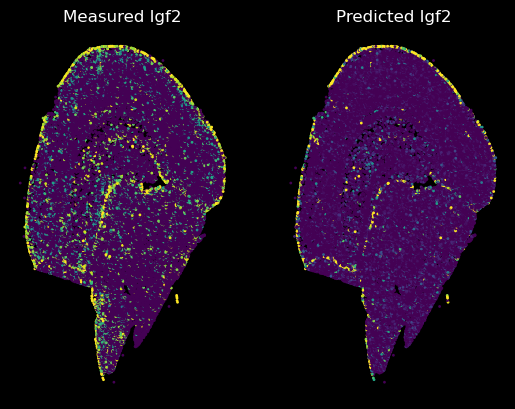

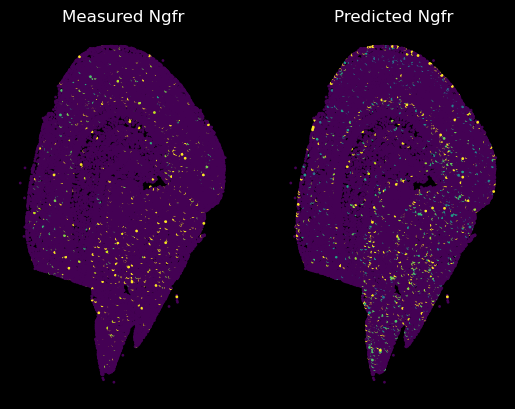

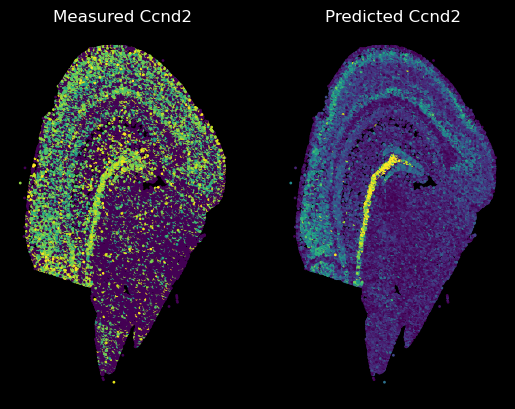

In [11]:
Gene_set = ['Igf2', 'Ngfr', 'Ccnd2']

# Metric storage
Correlations_Pearson = pd.Series(index = Gene_set)
Correlations_Spearman = pd.Series(index = Gene_set)
RMSE = pd.Series(index = Gene_set)
SSIM = pd.Series(index = Gene_set)

# Function to rasterise the expression data
def rasterise_expression(x_coords, y_coords, values, bins=100):
    stat, _, _, _ = st.binned_statistic_2d(x_coords, y_coords, values, statistic='mean', bins=bins)
    return np.nan_to_num(stat)  # Replace NaNs for SSIM compatibility
def normalise_raster(r):
    return (r - np.min(r)) / (np.max(r) - np.min(r) + 1e-8)

plt.style.use('dark_background')

for i in Gene_set:
  Imp_Genes = SpaGE(adata_st_df.drop(i,axis=1),adata_sc_df, n_pv=30, genes_to_predict = [i])
  Correlations_Pearson[i] = st.pearsonr(adata_st_df[i], Imp_Genes[i])[0]
  Correlations_Spearman[i] = st.spearmanr(adata_st_df[i],Imp_Genes[i])[0]
  RMSE[i] = root_mean_squared_error(adata_st_df[i], Imp_Genes[i])

  true_raster = rasterise_expression(adata_st.obs['center_x'], adata_st.obs['center_y'], adata_st_df[i])
  pred_raster = rasterise_expression(adata_st.obs['center_x'], adata_st.obs['center_y'], Imp_Genes[i])
  true_raster = normalise_raster(true_raster)
  pred_raster = normalise_raster(pred_raster)
  SSIM[i] = ssim(true_raster, pred_raster, data_range=1.0)
  
  print(i)

  fig, (ax1, ax2) = plt.subplots(1, 2)
  ax1.axis('off')
  cmap = adata_st_df[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)        # Sets a maximum values for the 99th percentile
  ax1.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax1.set_title('Measured ' + i, fontsize = 12)
  ax1.set_ylabel(i)

  ax2.axis('off')
  cmap = Imp_Genes[i]
  cmap[cmap > np.percentile(cmap,99)] = np.percentile(cmap,99)
  ax2.scatter(adata_st.obs['center_x'],adata_st.obs['center_y'],s=1,c=cmap)
  ax2.set_title('Predicted ' + i, fontsize = 12)

In [14]:
print(f'Pearson Correlations: \n{Correlations_Pearson}')
print(f'Spearman Correlations: \n{Correlations_Spearman}')
print(f'RMSE: \n{RMSE}')
print(f'SSIM: \n{SSIM}')

Pearson Correlations: 
Igf2     0.378481
Ngfr     0.025268
Ccnd2    0.408446
dtype: float64
Spearman Correlations: 
Igf2     0.158676
Ngfr     0.022690
Ccnd2    0.376354
dtype: float64
RMSE: 
Igf2     1.649040
Ngfr     0.594312
Ccnd2    2.638429
dtype: float64
SSIM: 
Igf2     0.407589
Ngfr     0.381131
Ccnd2    0.466503
dtype: float64
